In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

In [14]:
df_index = pd.read_csv('economic_index.csv')
df_index.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [18]:
df_index.drop(columns=['Unnamed: 0','year','month'], inplace=True)

In [19]:
df_index.head()

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [20]:
df_index.isna().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

<Axes: >

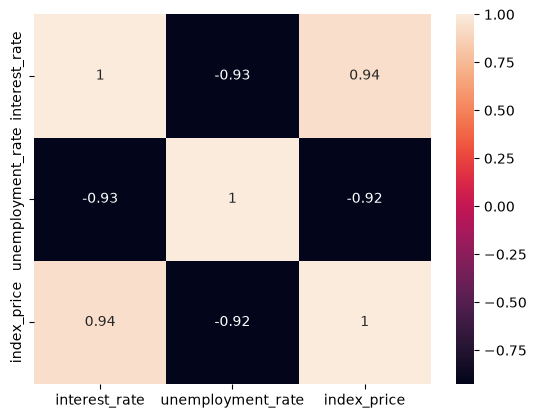

In [21]:
corr = df_index.corr()
sns.heatmap(corr, annot=True)

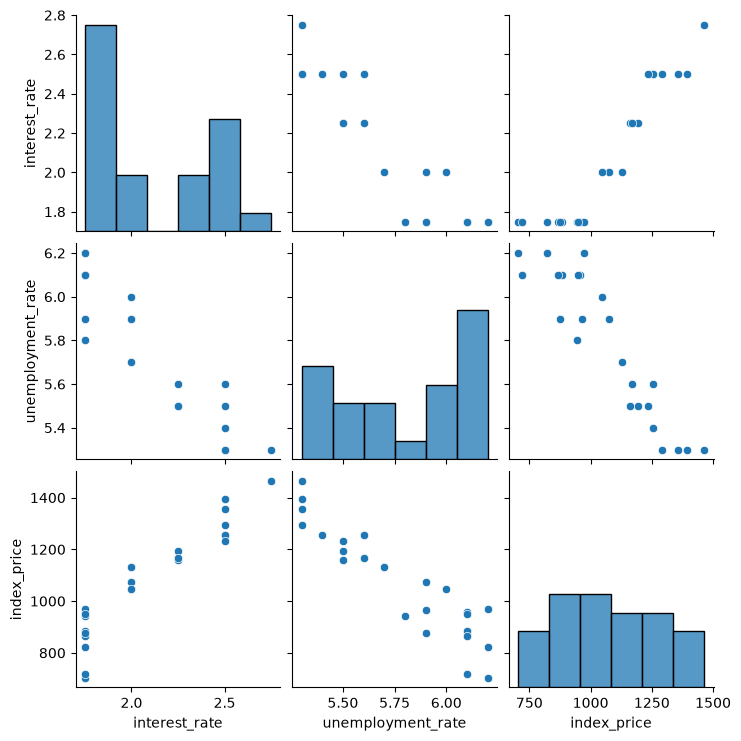

In [22]:
sns.pairplot(df_index)

<Axes: xlabel='interest_rate', ylabel='unemployment_rate'>

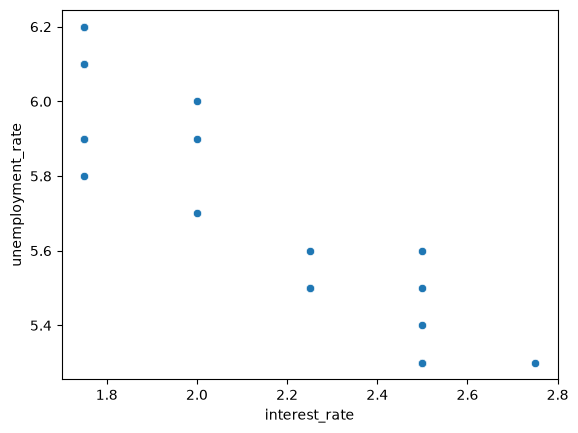

In [26]:
sns.scatterplot(x='interest_rate',y='unemployment_rate',data=df_index)

In [28]:
# Independent and Dependent Features

X = df_index.drop('index_price', axis=1)
y = df_index['index_price']

In [30]:
X.head()

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4


In [31]:
# train-test-split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.25, random_state = 42
)

<Axes: xlabel='interest_rate', ylabel='index_price'>

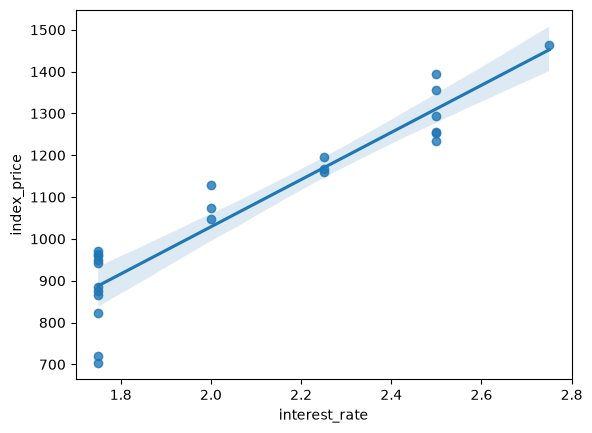

In [34]:
sns.regplot(x = 'interest_rate', y = 'index_price', data = df_index)

<Axes: xlabel='unemployment_rate', ylabel='index_price'>

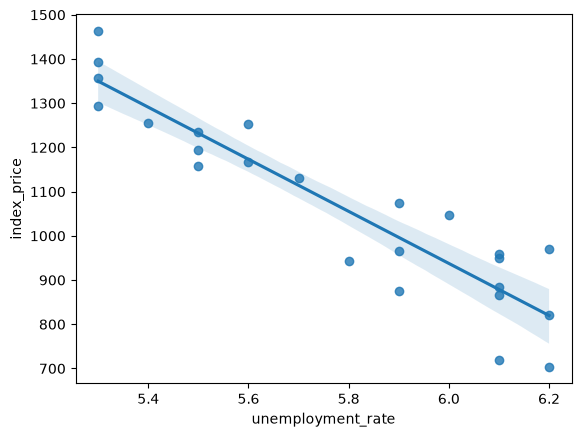

In [36]:
sns.regplot(x = 'unemployment_rate', y = 'index_price', data = df_index)

In [37]:
# scaling data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [38]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [39]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 88.27,-116.26]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1053
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[5.87,1.23]"


In [58]:
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

Coefficient: [  88.27275507 -116.25716066]
Intercept: 1053.4444444444443


In [46]:
# cross validation


from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv = 5,
    scoring = 'r2'
)

print('Scores:')
for i in range(0, 5):
    print(f'fold {i+1} r2 : {scores[i]}')

Scores:
fold 1 r2 : 0.96373611098815
fold 2 r2 : 0.6831026404513195
fold 3 r2 : 0.8067959943810017
fold 4 r2 : 0.7935509181843349
fold 5 r2 : 0.96849166139594


In [48]:
y_pred = model.predict(X_test)

In [49]:
# Performance Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

n = X_test.shape[0]
p = X_test.shape[1]

adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("Adjusted R2 Score:", adjusted_r2)


MAE: 59.935781523235484
MSE: 5793.762887712569
RMSE: 76.11677139574805
R2 Score: 0.8278978091457145
Adjusted R2 Score: 0.7131630152428576


# Assumptions

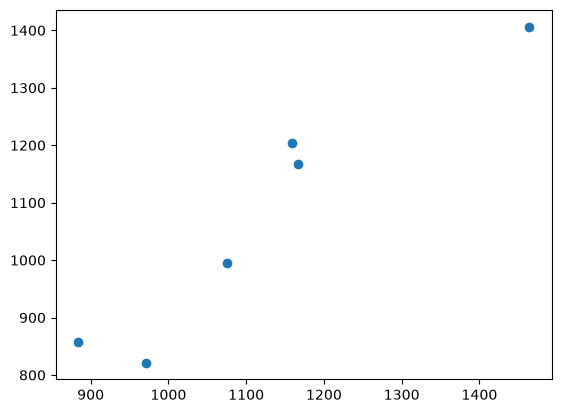

In [50]:
plt.scatter(y_test, y_pred)

In [52]:
residuals = y_test - y_pred
print("Residuals:\n", residuals)

Residuals:
 8     -45.227704
16    149.349481
0      57.486996
18     26.291104
11     80.090077
9      -1.169327
Name: index_price, dtype: float64


In [55]:
# OLS Linear Regression

import statsmodels.api as sm

model_ols = sm.OLS(y_train, X_train).fit()

In [56]:
print(model_ols.summary())

                                 OLS Regression Results                                
Dep. Variable:            index_price   R-squared (uncentered):                   0.035
Model:                            OLS   Adj. R-squared (uncentered):             -0.086
Method:                 Least Squares   F-statistic:                             0.2880
Date:                Wed, 21 Oct 2026   Prob (F-statistic):                       0.754
Time:                        16:16:27   Log-Likelihood:                         -150.85
No. Observations:                  18   AIC:                                      305.7
Df Residuals:                      16   BIC:                                      307.5
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------